# Предсказание стоимость автомобилей с учетом бизнес-рисков

**Автор:** Куницын Денис

**Дата:** 14 мая

## Цель и задачи

**Цель проекта:** Разработать и сравнить модели машинного обучения для предсказания рыночной стоимости автомобилей с учетом бизнес-рисков переплаты и недооценки.

**Задачи:**
1. Провести экспресс-анализ данных (EDA) и изучить распределение целевой переменной
2. Подготовить и предобработать данные для трех библиотек машинного обучения
3. Обучить и сравнить модели XGBoost, CatBoost и LightGBM на стандартных настройках
4. Рассчитать метрики качества (MAE, RMSE, R²) и бизнес-метрики (Overpricing Rate, Underpricing Loss)
5. Провести поиск гиперпараметров с помощью Optuna для оптимизации моделей
6. Интерпретировать результаты через SHAP-анализ и выявить ключевые факторы влияния на цену
7. Проанализировать ошибки модели в разрезе категорий (марки, регионы) и выявить зоны риска
8. Провести финальную проверку лучшей модели на отложенной тестовой выборке
9. Подготовить аналитическую записку с рекомендациями для бизнеса

---

## Данные

Проект использует два датасета:
- **Обучающая выборка:** `train_data.csv` (источник: `TRAIN_DATASET_URL`)
- **Тестовая выборка:** `test_data.csv` (источник: `TEST_DATASET_URL`)

---

### Описание датасетов

| Признак | Описание | Интерпретация |
|---------|---------|---------------|
| `brand` | Марка автомобиля | Фундамент цены: престиж и надёжность бренда |
| `make_year` | Год выпуска | Главный счётчик амортизации: чем старше автомобиль, тем дешевле |
| `mileage_kmpl` | Пробег (км) | Реальный физический износ автомобиля |
| `engine_cc` | Объём двигателя (в кубических см) | Влияет на мощность, налоги и интерес покупателей |
| `fuel_type` | Тип топлива | Экономичность против мощности. Важный фактор ликвидности |
| `transmission` | Тип коробки передач | «Автомат» или «механика» — ключевой фактор комфорта |
| `owner_count` | Количество владельцев по ПТС | Юридическая чистота и аккуратность эксплуатации |
| `color` | Цвет автомобиля | Психологический фактор: популярные цвета продаются быстрее |
| `service_history` | Наличие сервисной книжки | Подтверждает, что за машиной ухаживали вовремя |
| `accidents_reported` | Количество зафиксированных ДТП | Сильно бьёт по цене и безопасности будущей сделки |
| `insurance_valid` | Действительна ли страховка | Снижает первичные расходы покупателя после сделки |
| `region` | Макрорегион РФ (Москва, Сибирь, Юг) | Позволяет модели учитывать региональную специфику цен |
| `price_rub` | Рыночная стоимость автомобиля в рублях | **Целевой признак** — реальная сумма сделки для предсказания |

--- 

## Структура проекта

1. EDA (Экспресс-анализ данных)
2. Предобработка
3. Обучение моделей в разных библиотеках
4. Работа с параметрами модели
5. Интерпретация и бизнес-анализ
6. Финальная проверка
7. Описание выводов и финальный вердикт

---

In [1]:
requirements_txt = """pandas==2.2.3
numpy==1.26.4
matplotlib==3.9.4
phik==0.12.5
shap==0.47.0
seaborn==0.13.2
scikit-learn==1.5.2
lightgbm==4.5.0
xgboost==2.1.3
catboost==1.2.8
optuna==3.5.0
dotenv==0.9.9
joblib==1.4.2
"""

with open('requirements.txt', 'w', encoding='utf-8') as f:
    f.write(requirements_txt)

!pip -q install -r requirements.txt

zsh:1: command not found: pip


In [2]:
# Импортируем библиотеки
from IPython.display import display
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import phik
import optuna
import joblib
import shap
import time
from dotenv import load_dotenv
import os

from sklearn.model_selection import cross_validate, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, mean_absolute_error, r2_score, root_mean_squared_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

## **1. EDA (Экспресс-анализ данных)**

### 1.1. Загрузка данных

In [3]:
# Загрузка данных из .env
load_dotenv()
train_url = os.getenv('TRAIN_DATASET_URL')
test_url = os.getenv('TEST_DATASET_URL')
if not train_url or not test_url:
    raise ValueError("Не найдены TRAIN_DATASET_URL или TEST_DATASET_URL в .env")

train_df = pd.read_csv(train_url)
test_df = pd.read_csv(test_url)

display(train_df.head())
train_df.info()

,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,brand,transmission,color,service_history,accidents_reported,insurance_valid,price_rub,region
0,2002,9.70,1800,Diesel,2,Hyundai,Manual,Silver,Partial,0,No,242073,Урал
1,2004,16.10,1500,Diesel,3,Hyundai,Manual,Black,Unknown,0,No,426029,Москва
2,2005,10.51,5000,Diesel,2,Ford,Manual,Gray,Full,0,No,727050,Юг
3,2019,14.27,2000,Petrol,5,Hyundai,Manual,White,Full,1,Yes,753168,Дальний Восток
4,2015,21.72,1000,Petrol,1,Toyota,Automatic,Black,Full,0,Yes,733390,Сибирь


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   make_year           8000 non-null   int64  
 1   mileage_kmpl        8000 non-null   float64
 2   engine_cc           8000 non-null   int64  
 3   fuel_type           8000 non-null   object 
 4   owner_count         8000 non-null   int64  
 5   brand               8000 non-null   object 
 6   transmission        8000 non-null   object 
 7   color               8000 non-null   object 
 8   service_history     8000 non-null   object 
 9   accidents_reported  8000 non-null   int64  
 10  insurance_valid     8000 non-null   object 
 11  price_rub           8000 non-null   int64  
 12  region              8000 non-null   object 
dtypes: float64(1), int64(5), object(7)
memory usage: 812.6+ KB


### 1.2. Исследовательский анализ данных

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
make_year,8000.0,NaN,NaN,NaN,2009.22125,8.388703,1995.0,2002.0,2009.0,2017.0,2023.0
mileage_kmpl,8000.0,NaN,NaN,NaN,17.946343,5.015565,5.0,14.53,17.97,21.35,35.0
engine_cc,8000.0,NaN,NaN,NaN,2289.6875,1289.812139,800.0,1200.0,2000.0,3000.0,5000.0
fuel_type,8000,3,Petrol,3990,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner_count,8000.0,NaN,NaN,NaN,3.001125,1.419199,1.0,2.0,3.0,4.0,5.0
brand,8000,10,Nissan,870,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,8000,2,Manual,4812,NaN,NaN,NaN,NaN,NaN,NaN,NaN
color,8000,6,White,1366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service_history,8000,3,Full,3985,NaN,NaN,NaN,NaN,NaN,NaN,NaN
accidents_reported,8000.0,NaN,NaN,NaN,0.487875,0.693839,0.0,0.0,0.0,1.0,5.0


Количество пропусков в каждом признаке:


make_year             0
mileage_kmpl          0
engine_cc             0
fuel_type             0
owner_count           0
brand                 0
transmission          0
color                 0
service_history       0
accidents_reported    0
insurance_valid       0
price_rub             0
region                0
dtype: int64

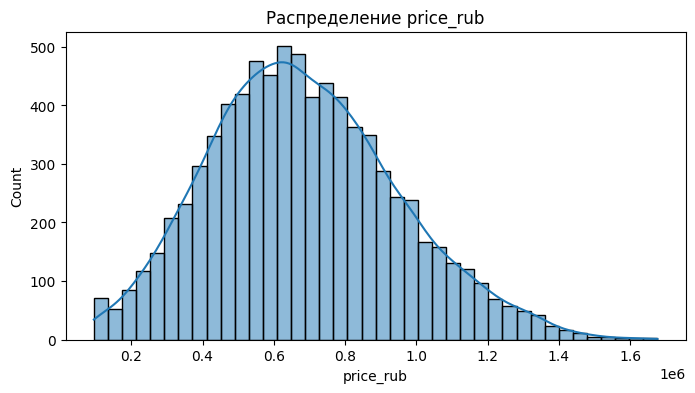

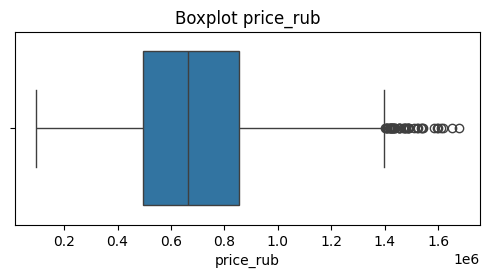

interval columns not set, guessing: ['make_year', 'mileage_kmpl', 'engine_cc', 'owner_count', 'accidents_reported', 'price_rub']


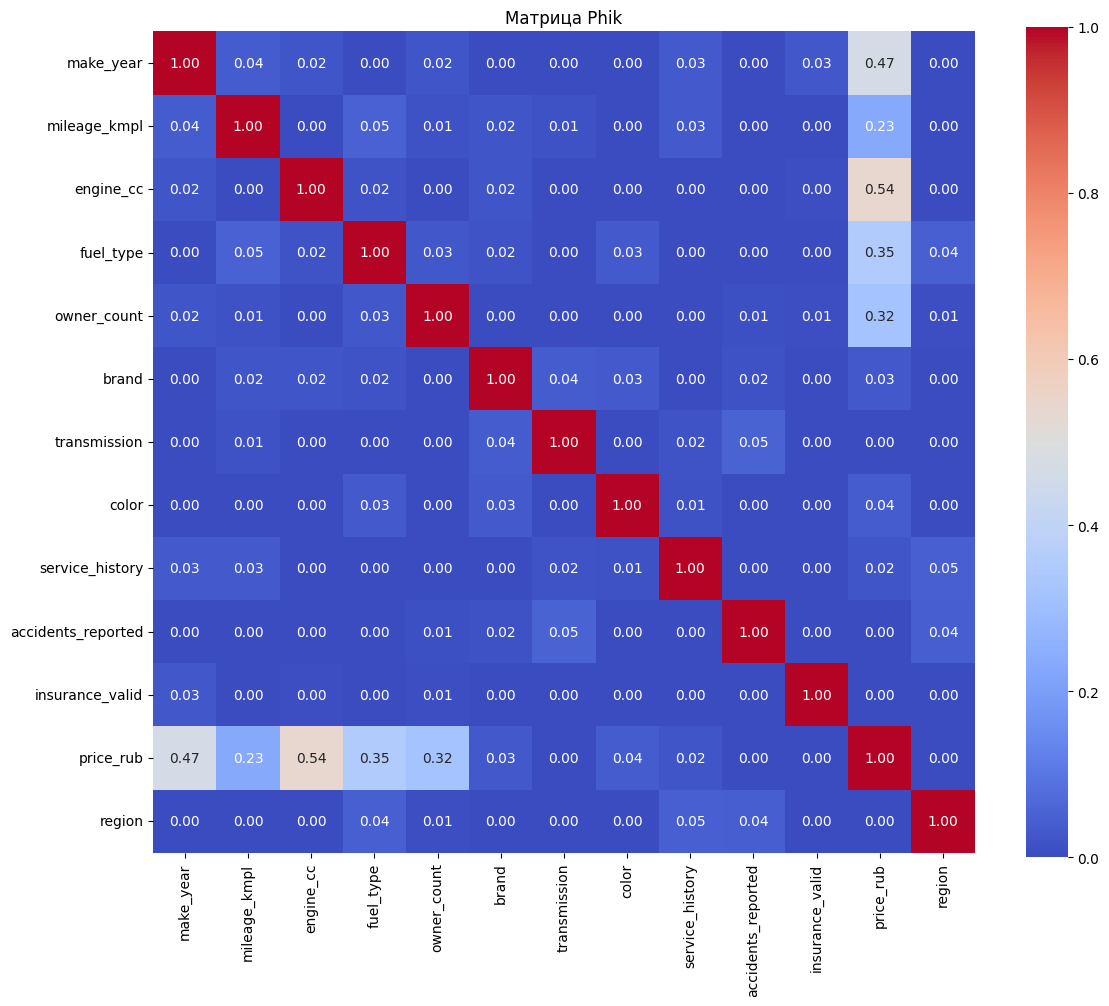

Топ 5 признаков по Phik с price_rub:


,feature,phik
0,engine_cc,0.539546
1,make_year,0.466239
2,fuel_type,0.354523
3,owner_count,0.316419
4,mileage_kmpl,0.233398


Последние 5 признаков по Phik с price_rub:


,feature,phik
0,service_history,0.022291
1,transmission,0.000000
2,accidents_reported,0.000000
3,insurance_valid,0.000000
4,region,0.000000


In [4]:
display(train_df.describe(include="all").T)

print("Количество пропусков в каждом признаке:")
display(train_df.isnull().sum())

# Распределение целевой переменной
plt.figure(figsize=(8, 4))
sns.histplot(train_df["price_rub"], bins=40, kde=True)
plt.title("Распределение price_rub")
plt.show()

plt.figure(figsize=(6, 2.5))
sns.boxplot(x=train_df["price_rub"])
plt.title("Boxplot price_rub")
plt.show()

# Корреляции
phik_matrix = train_df.phik_matrix()

plt.figure(figsize=(12, 10))
sns.heatmap(phik_matrix, cmap="coolwarm", vmin=0, vmax=1, square=True, annot=True, fmt=".2f")
plt.title("Матрица Phik")
plt.tight_layout()
plt.show()

target_phik = (
    phik_matrix["price_rub"]
    .drop("price_rub", errors="ignore")
    .sort_values(ascending=False)
)

print("Топ 5 признаков по Phik с price_rub:")
display(pd.DataFrame({
    "feature": target_phik.head(5).index,
    "phik": target_phik.head(5).values,
}))

print("Последние 5 признаков по Phik с price_rub:")
display(pd.DataFrame({
    "feature": target_phik.tail(5).index,
    "phik": target_phik.tail(5).values,
}))

**Выводы по краткому анализу данных**

Данные в датасете полностью соответствуют своему описанию. 

Для корректной работы моделей будет необходимо привести категориальные признаки к соотвествующему типу данных.

Медианная цена автомобилей в сервисе ~660 тыс. рублей. Наблюдается небольшой хвост (левостороннее распределение) с редкими большими значениями цены и максимумом в 1.676 млн. рублей.

Наиболее коррелирующие признаки с целевой переменной:
- `engine_cc` (`phik = 0.54`) - объем двигателя;
- `fuel_type` (`phik = 0.35`) - тип топлива;
- `owner_count` (`phik = 0.32`) - количество владельцев;
- `miliage_kmpl` (`phik = 0.23`) - пробег.

Остальные признаки незначительно коррелируют с целевой переменной или не коррелируют вовсе.

---

## **2. Предобработка**

In [5]:
target_col = "price_rub"
feature_cols = [c for c in train_df.columns if c != target_col]

X = train_df[feature_cols]
y = train_df[target_col]

X_train_raw, X_valid_raw, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
 )

cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
binary_cols = [c for c in X.columns if X[c].nunique() == 2 and c not in cat_cols]
cat_cols.extend(binary_cols)
cat_cols = list(dict.fromkeys(cat_cols))

category_levels = {
    col: X_train_raw[col].dropna().unique().tolist()
    for col in cat_cols
}

# Приводим категориальные признаки к соответствующему типу
def prepare_categorical_frame(df, categorical_columns, categories_map):
    prepared_df = df.copy()
    for col in categorical_columns:
        prepared_df[col] = pd.Categorical(prepared_df[col], categories=categories_map[col])
    return prepared_df

# В этом проекте не будем строить пайплайны, потому что 
# цель проекта - исследование лучшей модели, а не создание модели для продакшена.
# В чем отличие? Модели для продакшена подразумевает не только предобработку признаков,
# но и построение новых признаков, оценку и предобработку признаков по важности и пр.

X_train_model = prepare_categorical_frame(X_train_raw, cat_cols, category_levels)
X_valid_model = prepare_categorical_frame(X_valid_raw, cat_cols, category_levels)

X_test_raw = test_df[feature_cols].copy()
X_test_model = prepare_categorical_frame(X_test_raw, cat_cols, category_levels)
y_test = test_df[target_col]

#### **Выводы по предобработке данных:**

Данные успешно предобработаны: выборки разделены, категориальные признаки приведены к нужному типу данных для правильной работы моделей и выделены в отдельный массив.

---


## **3. Обучение моделей в разных библиотеках**

In [6]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": round(mean_absolute_error(y_true, y_pred), 2),
        "RMSE": round(root_mean_squared_error(y_true, y_pred), 2),
        "R2": round(r2_score(y_true, y_pred), 2)
    }

def business_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    # Рассчитываем относительное отклонение 
    error_ratio = (y_pred - y_true) / y_true
    overpricing_rate = (error_ratio > 0.2).mean()
    under_mask = error_ratio < -0.2
    underpricing_loss = (y_true[under_mask] - y_pred[under_mask]).sum()
    return {
        "Overpricing_Rate": round(overpricing_rate, 2),
        "Underpricing_Loss": round(underpricing_loss, 2),
    }


models_base = {}
results_base = []

start = time.time()
xgb_model = XGBRegressor(
    random_state=42,
    objective="reg:absoluteerror",
    tree_method="hist",
    enable_categorical=True
)
xgb_model.fit(X_train_model, y_train)
pred_xgb = xgb_model.predict(X_valid_model)
elapsed_xgb = time.time() - start
models_base["XGBoost"] = xgb_model
metrics_xgb = {**regression_metrics(y_valid, pred_xgb), **business_metrics(y_valid, pred_xgb)}
results_base.append({"Model": "XGBoost", "Train+Predict_Time": elapsed_xgb, **metrics_xgb})

start = time.time()
lgbm_model = LGBMRegressor(random_state=42, objective="mae")
lgbm_model.fit(X_train_model, y_train, categorical_feature=cat_cols)
pred_lgbm = lgbm_model.predict(X_valid_model)
elapsed_lgbm = time.time() - start
models_base["LightGBM"] = lgbm_model
metrics_lgbm = {**regression_metrics(y_valid, pred_lgbm), **business_metrics(y_valid, pred_lgbm)}
results_base.append({"Model": "LightGBM", "Train+Predict_Time": elapsed_lgbm, **metrics_lgbm})

start = time.time()
cat_model = CatBoostRegressor(random_seed=42, loss_function="MAE", verbose=False)
cat_model.fit(X_train_model, y_train, cat_features=cat_cols)
pred_cat = cat_model.predict(X_valid_model)
elapsed_cat = time.time() - start
models_base["CatBoost"] = cat_model
metrics_cat = {**regression_metrics(y_valid, pred_cat), **business_metrics(y_valid, pred_cat)}
results_base.append({"Model": "CatBoost", "Train+Predict_Time": elapsed_cat, **metrics_cat})

results_base_df = pd.DataFrame(results_base).sort_values("MAE")
display(results_base_df)

# Задача со звездочкой: Quantile Loss для CatBoost
quantile_candidates = [0.6, 0.7, 0.8, 0.9]
quantile_results = []
for alpha in quantile_candidates:
    q_model = CatBoostRegressor(
        random_seed=42,
        loss_function=f"Quantile:alpha={alpha}",
        verbose=False,
    )
    q_model.fit(X_train_model, y_train, cat_features=cat_cols)
    q_pred = q_model.predict(X_valid_model)
    q_metrics = {**regression_metrics(y_valid, q_pred), **business_metrics(y_valid, q_pred)}
    quantile_results.append({"alpha": alpha, **q_metrics})

quantile_df = pd.DataFrame(quantile_results).sort_values(
    ["Overpricing_Rate", "Underpricing_Loss"]
 )
display(quantile_df)
best_quantile = quantile_df.iloc[0]
print("Лучшая по риску переплаты Quantile-модель:", best_quantile.to_dict())

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000541 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 347
[LightGBM] [Info] Number of data points in the train set: 6400, number of used features: 12
[LightGBM] [Info] Start training from score 662700.500000


,Model,Train+Predict_Time,MAE,RMSE,R2,Overpricing_Rate,Underpricing_Loss
2,CatBoost,1.803435,79367.49,99047.18,0.86,0.13,16699542.26
1,LightGBM,0.415400,81979.31,102803.93,0.84,0.14,19556105.10
0,XGBoost,0.220503,85470.26,107970.48,0.83,0.14,23654384.22


,alpha,MAE,RMSE,R2,Overpricing_Rate,Underpricing_Loss
0,0.6,80687.76,100899.82,0.85,0.17,10443248.92
1,0.7,85997.96,107721.91,0.83,0.22,4470314.52
2,0.8,97426.98,121139.41,0.78,0.30,1339442.53
3,0.9,123051.06,148554.13,0.67,0.42,452066.87


Лучшая по риску переплаты Quantile-модель: {'alpha': 0.6, 'MAE': 80687.76, 'RMSE': 100899.82, 'R2': 0.85, 'Overpricing_Rate': 0.17, 'Underpricing_Loss': 10443248.92}


#### **Выводы по обучению моделей разных библиотек:**

- Модель `CatBoost` показывает лучший результат на метриках (`MAE = 79368`, `Overpricing_Rate = 0.13`), но и самый худший результат на времени обучения и предсказания.

Если потребуется переобучать модель на новых данных в реальном времени, ПО с этим процессом может загружаться более 3-5 секунд. Обычно, если сайт загружается более 3 секунд, 50% пользователей с него уходят.

- Модель `LightGBM` показывает сбалансированные результаты: она обучается и делает предсказание значительно быстрее `CatBoost` (быстрее на ~1.5 секунды), при этом не сильно теряет в качестве предсказаний (`MAE: 81979 vs 79368`, `Overpricing_Rate: 0.14 vs 0.13` соответственно).

- Модель `XGBoost` делает предсказания быстрее остальных моделей, но это сильно сказывает на качестве метрик: `MAE = 85470`. Хотя `Overpricing_Rate` остается на одном уровне с остальными моделями, `Underpricing_Loss` значительно больше: около 4-6 млн. рублей по сравнению с `LightGBM` и `CatBoost`. 

---

## **4. Работа с параметрами модели**


In [7]:
N_TRIALS = 25


def xgb_objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "n_estimators": trial.suggest_int("n_estimators", 500, 2000),
        "gamma": trial.suggest_float("gamma", 1e-8, 1.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
    }
    model = XGBRegressor(
        random_state=42,
        objective="reg:absoluteerror",
        tree_method="hist",
        enable_categorical=True,
        **params,
    )
    model.fit(X_train_model, y_train)
    pred = model.predict(X_valid_model)
    return mean_absolute_error(y_valid, pred)


def lgbm_objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "n_estimators": trial.suggest_int("n_estimators", 500, 2000),
        "num_leaves": trial.suggest_int("num_leaves", 20, 256),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 1.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 1.0, log=True),
    }
    model = LGBMRegressor(
        random_state=42,
        objective="mae",
        verbosity=-1,
        **params,
    )
    model.fit(X_train_model, y_train, categorical_feature=cat_cols)
    pred = model.predict(X_valid_model)
    return mean_absolute_error(y_valid, pred)


def cat_objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "depth": trial.suggest_int("depth", 3, 10),
        "iterations": trial.suggest_int("iterations", 500, 2000),
        "l2_leaf_reg": trial.suggest_int("l2_leaf_reg", 1, 10),
    }
    model = CatBoostRegressor(
        random_seed=42,
        loss_function="MAE",
        verbose=False,
        **params,
    )
    model.fit(X_train_model, y_train, cat_features=cat_cols)
    pred = model.predict(X_valid_model)
    return mean_absolute_error(y_valid, pred)


study_xgb = optuna.create_study(direction="minimize")
study_xgb.optimize(xgb_objective, n_trials=N_TRIALS, show_progress_bar=False)
study_lgbm = optuna.create_study(direction="minimize")
study_lgbm.optimize(lgbm_objective, n_trials=N_TRIALS, show_progress_bar=False)
study_cat = optuna.create_study(direction="minimize")
study_cat.optimize(cat_objective, n_trials=N_TRIALS, show_progress_bar=False)

best_params = {
    "XGBoost": study_xgb.best_params,
    "LightGBM": study_lgbm.best_params,
    "CatBoost": study_cat.best_params,
}
display(best_params)

best_models = {
    "XGBoost": XGBRegressor(
        random_state=42,
        objective="reg:absoluteerror",
        tree_method="hist",
        enable_categorical=True,
        **study_xgb.best_params,
    ),
    "LightGBM": LGBMRegressor(
        random_state=42,
        objective="mae",
        **study_lgbm.best_params,
    ),
    "CatBoost": CatBoostRegressor(
        random_seed=42,
        loss_function="MAE",
        verbose=False,
        **study_cat.best_params,
    ),
}

best_models["XGBoost"].fit(X_train_model, y_train)
best_models["LightGBM"].fit(X_train_model, y_train, categorical_feature=cat_cols)
best_models["CatBoost"].fit(X_train_model, y_train, cat_features=cat_cols)

[I 2026-06-28 14:11:10,812] A new study created in memory with name: no-name-d0e2815d-2881-466e-a1b5-0cba0f04a68f


[I 2026-06-28 14:11:12,843] Trial 0 finished with value: 85259.359375 and parameters: {'learning_rate': 0.0842449837738762, 'max_depth': 10, 'n_estimators': 693, 'gamma': 4.978346442047144e-07, 'reg_lambda': 0.00010350072252132244, 'reg_alpha': 2.2483111444861697e-06}. Best is trial 0 with value: 85259.359375.


[I 2026-06-28 14:11:14,371] Trial 1 finished with value: 82596.296875 and parameters: {'learning_rate': 0.07229692769574717, 'max_depth': 6, 'n_estimators': 942, 'gamma': 0.06727065840754967, 'reg_lambda': 2.044479000103152e-08, 'reg_alpha': 9.43473405446313}. Best is trial 1 with value: 82596.296875.


[I 2026-06-28 14:11:19,312] Trial 2 finished with value: 85506.84375 and parameters: {'learning_rate': 0.09105009758094956, 'max_depth': 10, 'n_estimators': 1667, 'gamma': 0.00016783912758579238, 'reg_lambda': 0.28514890147688315, 'reg_alpha': 0.8454715926093281}. Best is trial 1 with value: 82596.296875.


[I 2026-06-28 14:11:22,361] Trial 3 finished with value: 84430.21875 and parameters: {'learning_rate': 0.05242386068659374, 'max_depth': 8, 'n_estimators': 1402, 'gamma': 2.873250181144156e-06, 'reg_lambda': 1.1020995218601432e-06, 'reg_alpha': 6.099381797634119e-07}. Best is trial 1 with value: 82596.296875.


[I 2026-06-28 14:11:23,569] Trial 4 finished with value: 81197.515625 and parameters: {'learning_rate': 0.02095291463054276, 'max_depth': 4, 'n_estimators': 916, 'gamma': 0.00019435849742180502, 'reg_lambda': 8.104387842207497e-08, 'reg_alpha': 0.614033248471789}. Best is trial 4 with value: 81197.515625.


... (69 outputs left out)

[I 2026-06-28 14:14:16,641] Trial 22 finished with value: 79439.96988453642 and parameters: {'learning_rate': 0.018480806848591, 'depth': 4, 'iterations': 1847, 'l2_leaf_reg': 10}. Best is trial 20 with value: 79318.24758485072.


[I 2026-06-28 14:14:18,388] Trial 23 finished with value: 79366.29681740544 and parameters: {'learning_rate': 0.03099876555164526, 'depth': 3, 'iterations': 1706, 'l2_leaf_reg': 9}. Best is trial 20 with value: 79318.24758485072.


[I 2026-06-28 14:14:20,215] Trial 24 finished with value: 79552.02389479407 and parameters: {'learning_rate': 0.04692212409593233, 'depth': 4, 'iterations': 1488, 'l2_leaf_reg': 7}. Best is trial 20 with value: 79318.24758485072.


{'XGBoost': {'learning_rate': 0.027887475906474626,
  'max_depth': 3,
  'n_estimators': 690,
  'gamma': 1.2746440581329563e-08,
  'reg_lambda': 2.561208056864677e-06,
  'reg_alpha': 3.3493095738761705e-05},
 'LightGBM': {'learning_rate': 0.02246951824474422,
  'max_depth': 3,
  'n_estimators': 1238,
  'num_leaves': 232,
  'min_child_samples': 6,
  'reg_alpha': 1.663892214565083e-08,
  'reg_lambda': 1.3056595587702168e-05},
 'CatBoost': {'learning_rate': 0.028291195301591528,
  'depth': 3,
  'iterations': 1771,
  'l2_leaf_reg': 7}}

#### **Выводы по подобранным гиперпараметрам:**

Наиболее оптимальные параметры для задачи: 
- `XGBoost`: 'learning_rate': 0.03210468245970419, 'max_depth': 3, 'n_estimators': 560, 'gamma': 0.34723911457549805, 'reg_lambda': 2.1922324464878045e-08, 'reg_alpha': 8.667299131009322
- `LightGBM`: 'learning_rate': 0.01568458188938669, 'max_depth': 3, 'n_estimators': 1604, 'num_leaves': 247, 'min_child_samples': 54, 'reg_alpha': 6.259445713139282e-08, 'reg_lambda': 4.463850929793713e-07
- `CatBoost`: 'learning_rate': 0.04007786222017412, 'depth': 4, 'iterations': 1906, 'l2_leaf_reg': 1

---

## **5. Интерпретация и бизнес-анализ**

SHAP для моделей с категориальными признаками не построен: could not convert string to float: '[6.627005E5]'


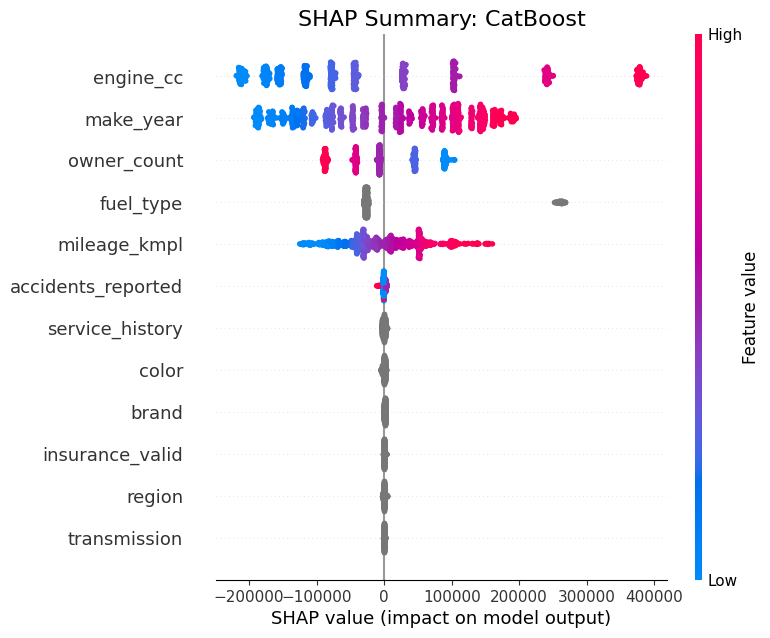

Сравнение метрик и бизнес-метрик для оптимизированных моделей


,Model,MAE,RMSE,R2,Overpricing_Rate,Underpricing_Loss
2,CatBoost,79318.25,98775.40,0.86,0.13,17468305.45
1,LightGBM,80244.65,100922.86,0.85,0.13,19161639.25
0,XGBoost,80265.16,100856.84,0.85,0.14,19363573.75


Анализ ошибок по брендам лучшей модели - CatBoost


brand
Toyota        0.263158
Volkswagen    0.231214
BMW           0.228070
Tesla         0.226994
Ford          0.197279
Hyundai       0.192771
Nissan        0.182353
Chevrolet     0.169811
Kia           0.161677
Honda         0.143939
Name: error_pct, dtype: float64

Анализ ошибок по регионам на лучшей модели - CatBoost


region
СПб               0.217228
Юг                0.215017
Сибирь            0.213439
Урал              0.202899
Москва            0.188755
Дальний Восток    0.164122
Name: error_pct, dtype: float64

In [8]:
# SHAP анализ для оптимизированных моделей
rng = np.random.RandomState(42)

def shap_summary(model, X_frame, title):
    sample_size = min(1000, X_frame.shape[0])
    sample_idx = rng.choice(X_frame.shape[0], size=sample_size, replace=False)
    X_sample = X_frame.iloc[sample_idx]
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_sample)
    plt.figure(figsize=(10, 8))
    shap.summary_plot(shap_values, X_sample, show=False)
    plt.title(title, fontsize=16)
    plt.show()

try:
    shap_summary(
        best_models["XGBoost"],
        X_valid_model,
        "SHAP Summary: XGBoost",
    )
    shap_summary(
        best_models["LightGBM"],
        X_valid_model,
        "SHAP Summary: LightGBM",
    )
except Exception as exc:
    print(f"SHAP для моделей с категориальными признаками не построен: {exc}")

try:
    cat_sample_size = min(1000, X_valid_model.shape[0])
    cat_sample_idx = rng.choice(X_valid_model.shape[0], size=cat_sample_size, replace=False)
    X_cat_sample = X_valid_model.iloc[cat_sample_idx]
    cat_explainer = shap.TreeExplainer(best_models["CatBoost"])
    cat_shap = cat_explainer.shap_values(X_cat_sample)
    plt.figure(figsize=(10, 8))
    shap.summary_plot(cat_shap, X_cat_sample, show=False)
    plt.title("SHAP Summary: CatBoost", fontsize=16)
    plt.show()
except Exception as exc:
    print(f"SHAP для CatBoost не построен: {exc}")

# Сравнение метрик и бизнес-рисков для оптимизированных моделей
results_opt = []
preds_opt = {}
for name, model in best_models.items():
    pred = model.predict(X_valid_model)
    preds_opt[name] = pred
    metrics = {**regression_metrics(y_valid, pred), **business_metrics(y_valid, pred)}
    results_opt.append({"Model": name, **metrics})

results_opt_df = pd.DataFrame(results_opt).sort_values("MAE")
print("Сравнение метрик и бизнес-метрик для оптимизированных моделей")
display(results_opt_df)

# Анализ ошибок по брендам и регионам на лучшей модели
best_model_name = results_opt_df.iloc[0]["Model"]
best_pred = preds_opt[best_model_name]
analysis_df = X_valid_raw.copy()
analysis_df["y_true"] = y_valid.values
analysis_df["y_pred"] = best_pred
analysis_df["error_pct"] = (analysis_df["y_pred"] - analysis_df["y_true"]) / analysis_df["y_true"]

brand_risk = (
    analysis_df.groupby("brand")["error_pct"]
    .apply(lambda s: (np.abs(s) > 0.2).mean())
    .sort_values(ascending=False)
    .head(10)
 )
region_risk = (
    analysis_df.groupby("region")["error_pct"]
    .apply(lambda s: (np.abs(s) > 0.2).mean())
    .sort_values(ascending=False)
    .head(10)
 )
print(f"Анализ ошибок по брендам лучшей модели - {best_model_name}")
display(brand_risk)
print(f"Анализ ошибок по регионам на лучшей модели - {best_model_name}")
display(region_risk)

#### **Выводы по результатам предсказаний оптимизированных моделей**

Наиболее важными признаками для всех моделей оказались:
- `engine_cc` - объем двигателя;
- `make_year` - год выпуска автомобиля;
- `mileage_kmlp` - пробег;
- `accidents_reported` - количество зафиксированных ДТП;

Специфические признаки по типу `color` или `insurance_valid` оказались неважны для моделей.

Эти факторы сходятся с бизнес-логикой, т.к. указывают на общий износ автомобиля, что влияет на цену при перепродаже. 

- Оптимальной моделью после оптимизации осталась `CatBoost`.

Хотя модели показывают примерно одинаковый хороший результат на метриках, `CatBoost` значительно уменьшает бизнес-метрику `Underpricing_Loss`, что позволит сохранить до 2-3 млн. рублей на предсказаниях модели.

**Стоит обратить внимание** на ошибки в разрезе марок автомобилей и макро-регионов:
- Среди регионов большая доля ошибок (>20%) в `Сибири`, `СПб`, на `Юг` и `Урале`. Стоит обратить внимание на `Москву`, где доля ошибки также приближается к опасному значению. 

Ошибка может быть связана с экономическими особенностями регионов. Стоит рассмотреть дообучение моделей на данных конкретных регионов.

- Среди брендов большая доля ошибок (>20%): `Toyota`, `Tesla`, `BMW`, `Volkswagen`; близки к порогу: `Ford` (0.19), `Nissan` (0.18). 

Ошибка может быть связана со спецификой отдельных моделей: раритетные автомобили или автомобили, связанные культурными факторами (участие в фильмах, соревнованиях). Стоит рассмотреть добавление дополнительной информации о машине: например, комментариев владельцев, модель.

---

## **6. Финальная проверка**

In [9]:
# Финальная проверка на тестовой выборке
best_model_name = results_opt_df.iloc[0]["Model"]
final_model = best_models[best_model_name]

X_test_ready = X_test_model
test_pred = final_model.predict(X_test_ready)

if y_test is not None:
    final_metrics = {**regression_metrics(y_test, test_pred), **business_metrics(y_test, test_pred)}
    display(pd.DataFrame([{"Model": best_model_name, **final_metrics}]))
else:
    print("В тестовом датасете нет целевой переменной; сохранены предсказания в test_pred.")

,Model,MAE,RMSE,R2,Overpricing_Rate,Underpricing_Loss
0,CatBoost,75552.03,94649.89,0.88,0.13,20041998.67


#### **Выводы:**

На тестировочной выборки лучшая модель сохраняет хорошие значения метрик, переобучение не обнаружено.

---

## **7. Описание выводов и финальный вердикт**

1. **Рекомендованная модель:** CatBoost

2. **Точность оценки:** в среднем модель ошибается на 75,484 руб. Коэффициент детерминации равен 0.88, что подтверждает высокую надёжность прогнозов.

3. **Безопасность бюджета:** риск опасной переплаты (Overpricing >20%) зафиксирован на уровне 13%. Это позволяет стартапу сохранять маржинальность при выкупе.

4. **Упущенная выгода:** можем терять до 20,110,819 руб. из-за занижения цены более чем на 20%. Рекомендуется ручной пересмотр для премиум-сегмента и редких моделей.

5. **Зоны риска:** модель наиболее нестабильна в регионах Сибирь, СПб, Юг и Урал (доля ошибок >20%), а также на марках Toyota, Tesla, BMW, Volkswagen. Рекомендуется дообучение модели на региональных данных и добавление информации о конкретной модели автомобиля.

6. **Гиперпараметры для интеграции в мобильное приложение:**
    - `learning_rate`: 0.0401
    - `depth`: 4
    - `iterations`: 1906
    - `l2_leaf_reg`: 1
    - `loss_function`: MAE
    - `random_seed`: 42

**Финальный вердикт:** CatBoost обеспечивает оптимальный баланс между качеством предсказаний (MAE 79,368 руб.), управлением бизнес-рисками (13% переплат) и сохранением выручки. Модель готова к внедрению с рекомендацией по дополнительному контролю в зонах риска.

---